In [1]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import SigmaClip

from photutils.background import (Background2D, MedianBackground,MADStdBackgroundRMS)
from photutils.segmentation import detect_sources
from photutils.utils import circular_footprint

In [2]:
# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------
BOX_SIZE = 100        # pixels; test e.g. 64, 128, 256
DETECTION_SIGMA = 3.0
N_PIXELS = 20
DILATION_RADIUS = 8   # grow detected-source masks

In [3]:
# ---------------------------------------------------------
# 1. Read Halpha flux and flux-error maps
# ---------------------------------------------------------
path = "/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits"
hdul = fits.open(path, memmap=True)
ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
#sii6716 = hdul["SII6716_FLUX"].data
#sii6730 = hdul["SII6730_FLUX"].data
#sii = sii6716 + sii6730

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
#sii6716_err = hdul["SII6716_FLUX_ERR"].data
#sii6730_err = hdul["SII6730_FLUX_ERR"].data
#sii_err = np.sqrt(sii6716_err**2 + sii6730_err**2)
print(hdul["HA6562_FLUX"].header.get("BUNIT"))

# ESO table gives fluxes in units of 1e-20
# erg s^-1 cm^-2 spaxel^-1
FLUX_UNIT = 1e-20

# Pixels with no usable coverage
coverage_mask = (~np.isfinite(ha) | ~np.isfinite(ha_err) | (ha_err <= 0))

None


In [4]:
# ---------------------------------------------------------
# 2. First rough background estimate
# ---------------------------------------------------------
sigma_clip = SigmaClip(sigma=3.0, maxiters=10)

bkg0 = Background2D(ha, box_size=BOX_SIZE, coverage_mask=coverage_mask,
                    sigma_clip=sigma_clip, bkg_estimator=MedianBackground(),
                    bkg_rms_estimator=MADStdBackgroundRMS(), filter_size=(3, 3),
                    # useful for a crowded galaxy
                    exclude_percentile=50.0)

initial_background = bkg0.background

In [5]:
# ---------------------------------------------------------
# 3. Find emission brighter than the local background
# ---------------------------------------------------------
residual = ha - initial_background

# Use the larger of:
#   - DAP flux uncertainty
#   - empirical local RMS from Background2D
noise = np.maximum(ha_err, bkg0.background_rms)

threshold = DETECTION_SIGMA * noise
threshold[coverage_mask] = np.inf

segm = detect_sources(residual, threshold, n_pixels=N_PIXELS, mask=coverage_mask)

In [6]:
# ---------------------------------------------------------
# 4. Turn detected sources into a larger mask
# ---------------------------------------------------------
if segm is not None:
    footprint = circular_footprint(radius=DILATION_RADIUS)
    source_mask = segm.make_source_mask(footprint=footprint)

else:
    source_mask = np.zeros(ha.shape, dtype=bool)

In [7]:
# ---------------------------------------------------------
# 5. Recalculate background with bright sources removed
# ---------------------------------------------------------
bkg = Background2D(ha, box_size=BOX_SIZE, mask=source_mask,
    coverage_mask=coverage_mask,
    sigma_clip=sigma_clip,
    bkg_estimator=MedianBackground(),
    bkg_rms_estimator=MADStdBackgroundRMS(),
    filter_size=(3, 3),
    exclude_percentile=50.0)

background_map = bkg.background
background_subtracted = ha - background_map

In [8]:
# ---------------------------------------------------------
# 6. Background distribution in physical units
# ---------------------------------------------------------
good = (~coverage_mask & ~source_mask & np.isfinite(background_map))
background_values = background_map[good] * FLUX_UNIT
np.save("background_values.npy", background_values)
print("\nHalpha background:")
for p in [5, 16, 50, 84, 95]:
    value = np.nanpercentile(background_values, p)
    print(f"{p:2d} percentile = {value:.3e} erg/s/cm2/spaxel")


Halpha background:
 5 percentile = 5.476e-19 erg/s/cm2/spaxel
16 percentile = 8.122e-19 erg/s/cm2/spaxel
50 percentile = 1.671e-18 erg/s/cm2/spaxel
84 percentile = 5.427e-18 erg/s/cm2/spaxel
95 percentile = 9.262e-18 erg/s/cm2/spaxel


In [9]:
# ---------------------------------------------------------
# 7. Empirical noise and background S/N
# ---------------------------------------------------------
good_snr = (good & (background_map > 0) & (ha_err > 0))
background_snr = background_map[good_snr] / ha_err[good_snr]

print("\nMedian background S/N =", np.nanmedian(background_snr))
print("16-84 percentile S/N =", np.nanpercentile(background_snr,[16, 84]))


Median background S/N = 8.001917
16-84 percentile S/N = [ 4.14647272 16.63220215]


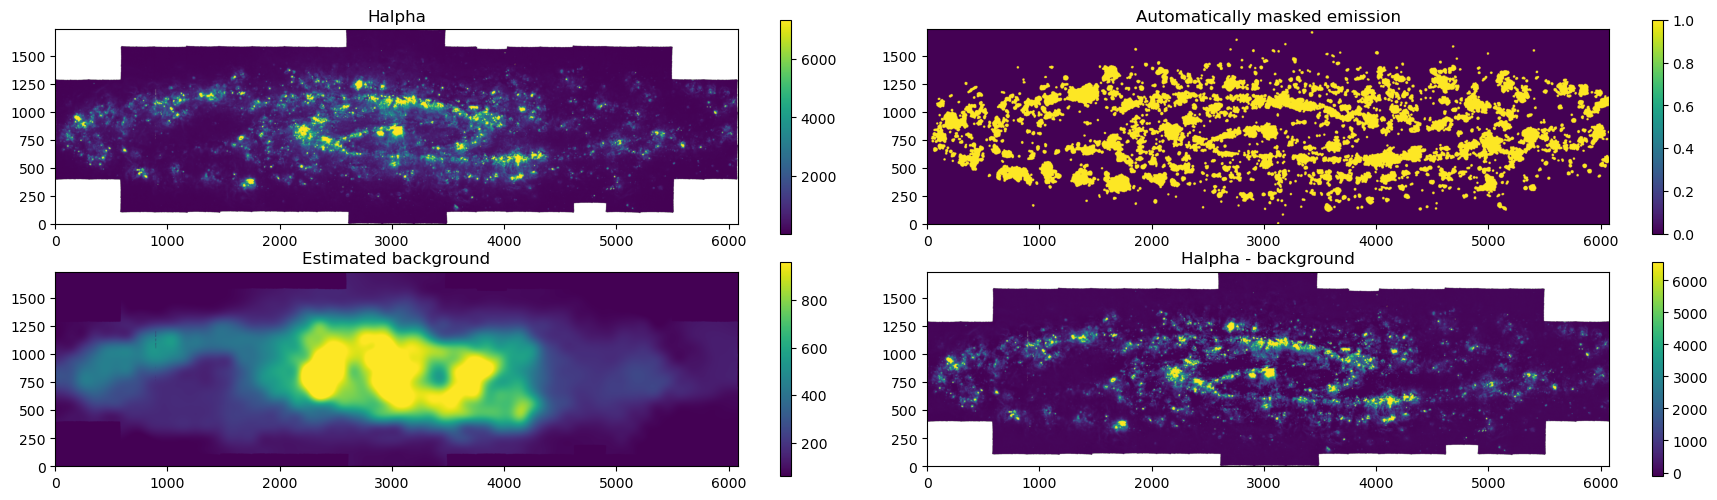

In [10]:
# ---------------------------------------------------------
# 8. Quick diagnostic plots
# ---------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(18, 5))

vmin, vmax = np.nanpercentile(ha[~coverage_mask], [5, 99])
im0 = ax[0, 0].imshow(ha, origin="lower", vmin=vmin, vmax=vmax)
ax[0, 0].set_title("Halpha")
fig.colorbar(im0, ax=ax[0, 0])

im1 = ax[0, 1].imshow(source_mask, origin="lower")
ax[0, 1].set_title("Automatically masked emission")
fig.colorbar(im1, ax=ax[0, 1])

bg_min, bg_max = np.nanpercentile(background_map[~coverage_mask], [5, 95])
im2 = ax[1, 0].imshow(background_map, origin="lower", vmin=bg_min, vmax=bg_max)
ax[1, 0].set_title("Estimated background")
fig.colorbar(im2, ax=ax[1, 0])

rmin, rmax = np.nanpercentile(background_subtracted[~coverage_mask], [5, 99])
im3 = ax[1, 1].imshow(background_subtracted, origin="lower", vmin=rmin, vmax=rmax)
ax[1, 1].set_title("Halpha - background")
fig.colorbar(im3, ax=ax[1, 1])

plt.tight_layout()
plt.show()